# VCC 2026 · Notebook 01 — A local "practice exam" for our predictions

**Why this notebook exists.** The final phase of the Virtual Cell Challenge (contexts D/E/F, Oct 22 → Nov 5)
is *blind*: no leaderboard, new cell lines, new target genes, and only the **last** entry counts. During
validation we only get **2 scored submissions per day**. So we need our own exam that we can take as often
as we like, graded by **Arc's official scorer** (`cell-eval2`, `vcc2026` profile) with the same scaling formula
as the leaderboard.

**What it does, step by step**

| § | Step | Output |
|---|------|--------|
| 1–2 | Settings and helpers | — |
| 3 | Look at our real VCC control cells (contexts A/B/C) | summary table |
| 4 | Functions that build a **proxy context**: a dataset where we *know* the true responses | functions |
| 5 | The **cell generator**: predicted expression profile → 400 realistic count cells; then build the proxy | `real.h5ad` |
| 6 | Build the official **scoring reference** for the proxy (the 0 and 1 ends of each metric's scale) | `bundle/` |
| 7 | Score a set of test predictions (copy-the-controls, the truth, the truth shrunk/inflated/noisy, …) | score table |
| 9 | Write a **VCC submission file** and validate it with `vcc prep --dry-run` | `.h5ad` |
| 10 | How to run all this on **TSUBAME 4.0** | instructions |

**The one idea to keep in mind.** We submit *cells*, not profiles. Four of the six metrics run a Wilcoxon
test of our 400 cells against 18,400 real control cells, gene by gene. If our cells don't look like real cells
(zero fraction, spread, library size), thousands of genes come out falsely "significant" and those metrics
collapse. §5's generator handles that by editing *real control cells*; §7 shows how much it matters.

Background on the metrics: `notes/VCC2026_brief.md` (§4).

**This notebook is stored twice**: `01_local_evaluation_harness.ipynb` and a paired plain-text copy
`01_local_evaluation_harness.py` (via *jupytext*). Open the `.ipynb` in Jupyter; it keeps both in sync. If you
edit the `.py` elsewhere, run `jupytext --sync notebooks/01_local_evaluation_harness.py` before using the
TSUBAME batch script.

## 0. How to run

* **On the Mac** (24 GB RAM): `MODE = "local_small"` with the synthetic proxy: 30 proxy perturbations, CPU
  scorer, about 10 minutes and ~14 GB peak RAM. From the project folder run `.venv/bin/jupyter lab`, open
  `notebooks/01_local_evaluation_harness.ipynb`, pick the **VCC (project .venv)** kernel, then
  *Kernel → Restart Kernel and Run All Cells*.
  The H1 proxy on the Mac first downloads 12 GB and needs more memory (~15–18 GB); prefer TSUBAME for it.
* **On TSUBAME 4.0**: `MODE = "tsubame_full"`: 300 perturbations, GPU scorer (gpudge, the DE engine the
  platform uses), on a `node_q` (1 × H100, 192 GB RAM). See §10.

`MODE` and `PROXY` can be set in §1 or with the environment variables `VCC_MODE` / `VCC_PROXY` (the batch
script uses those). **After changing them, always restart the kernel and run all cells**; several later
settings are derived from them.

## 1. Settings

In [1]:
import os
from pathlib import Path

# ---- Run mode ---------------------------------------------------------------------------------
# "local_small"  : Mac or small TSUBAME job. Small proxy (30 perturbations), CPU scorer (pdex).
# "tsubame_full" : TSUBAME GPU node. Full-size proxy (up to 300 perturbations), GPU scorer (gpudge).
MODE = os.environ.get("VCC_MODE", "local_small")

# ---- Which proxy context to build in §4–5 -------------------------------------------------------
# "synthetic" : made from our own control cells + known synthetic effects. No download needed.
#               Good for testing the pipeline; NOT realistic biology, and too kind to our generator (see §4a).
# "h1_2025"   : Arc's 2025 H1 hESC CRISPRi data (real biology, same 10x Flex chemistry). Downloads data (§4b).
PROXY = os.environ.get("VCC_PROXY", "synthetic")

# ---- Paths --------------------------------------------------------------------------------------
# The project folder is the one that contains `controls/` (the unzipped controls bundle).
# This notebook lives in `notebooks/`, so the project folder is its parent.
PROJECT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
CONTROLS_DIR = PROJECT / "controls"              # validation controls (A/B/C): used for §3 and the synthetic proxy
SUBMIT_DIR = CONTROLS_DIR                        # controls for the submission in §9. FINAL PHASE: unzip the D/E/F
                                                 # bundle into controls_DEF/ and set SUBMIT_DIR = PROJECT / "controls_DEF"
DATA_DIR = PROJECT / "data"                      # public datasets go here (§4b)
WORK = PROJECT / "work" / f"harness_{PROXY}_{MODE}"   # everything this notebook writes
RESULTS_LOG = PROJECT / "work" / "experiments.csv"    # one row per scored prediction, across runs

# ---- Sizes --------------------------------------------------------------------------------------
CELLS_PER_PERT = 400                             # fixed by the challenge
N_PERTS = 30 if MODE == "local_small" else 300   # proxy panel size (H1 has at most ~255 usable)
SEED = 0

# ---- Scorer engine ------------------------------------------------------------------------------
# On a GPU node, cell-eval2's 'auto' setting picks gpudge (the platform's DE engine).
# On a CPU-only machine we force the CPU engine pdex. DE numbers can differ slightly between the two engines,
# so only compare scores produced in the same MODE (experiments.csv records the mode).
USE_GPU = MODE == "tsubame_full"
CE_ENGINE = [] if USE_GPU else ["--set", "device=cpu", "--set", "de.backend=pdex"]
CE_COMMON = ["--preset", "vcc2026", "--pert-col", "target_gene", *CE_ENGINE]

WORK.mkdir(parents=True, exist_ok=True)
print(f"MODE={MODE}  PROXY={PROXY}  N_PERTS={N_PERTS}\nWORK=<project>/{WORK.relative_to(PROJECT)}")
assert CONTROLS_DIR.exists(), ("Download and unzip the controls first: "
                               "vcc datasets download controls -d . && unzip -o vcc_2026_controls.zip -d controls")

MODE=local_small  PROXY=synthetic  N_PERTS=30
WORK=<project>/work/harness_synthetic_local_small


## 2. Imports and small helpers

In [2]:
import json
import shutil
import subprocess
import sys
import time
from datetime import datetime, timezone

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

rng = np.random.default_rng(SEED)

# The cell-eval2 command-line tool installed in the same environment as this kernel.
CELL_EVAL2 = shutil.which("cell-eval2") or str(Path(sys.executable).with_name("cell-eval2"))
# The vcc CLI (uv tool install vcc-cli). Only needed in §9.
VCC = shutil.which("vcc") or str(Path.home() / ".local" / "bin" / "vcc")


def run_cmd(cmd, log_path=None):
    """Run a shell command, print how long it took, save its output to a log, and fail loudly on errors."""
    t0 = time.time()
    proc = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if log_path:
        Path(log_path).write_text(f"$ {' '.join(map(str, cmd))}\n\n{proc.stdout}\n{proc.stderr}")
    print(f"  {Path(cmd[0]).name} {cmd[1]} … exit={proc.returncode}  ({time.time() - t0:.0f} s)")
    if proc.returncode != 0:
        print(proc.stdout[-2000:], proc.stderr[-4000:])
        raise RuntimeError(f"command failed: {cmd[:2]}")
    return proc


def per_cell_cpm(X):
    """Counts → counts-per-million, cell by cell (each cell divided by its own total).
    This is exactly how the scorer normalizes cells before its Wilcoxon test and fold changes."""
    lib = np.asarray(X.sum(axis=1)).ravel().astype(np.float64)
    lib[lib == 0] = 1.0                                  # the scorer also treats empty cells this way
    return sp.diags(1e6 / lib) @ X


def mean_cpm(X):
    """Arithmetic mean of per-cell CPM over a group of cells (normalize first, then average)."""
    return np.asarray(per_cell_cpm(X).mean(axis=0)).ravel()

## 3. Our real VCC control cells at a glance

Each context file holds 18,400 non-targeting control cells (46 guides × 400 cells) of one anonymized cell
line, as raw counts on the 18,533-gene axis. These cells are (almost certainly) also the control group the
scorer uses, so they are the best possible templates for generating predicted cells.

In [3]:
genes = pd.read_csv(CONTROLS_DIR / "gene_names.csv")["gene_name"].to_numpy()     # file has a header row
panel = pd.read_csv(CONTROLS_DIR / "pert_counts.csv")["target_gene"].tolist()    # the 300 targets to predict
contexts = json.loads((CONTROLS_DIR / "manifest.json").read_text())["contexts"]   # ['A','B','C']

rows, pseudobulk = [], {}
for ctx in contexts:
    a = ad.read_h5ad(CONTROLS_DIR / f"context_{ctx}.h5ad")
    assert list(a.var_names) == list(genes), "gene order must match gene_names.csv"
    X = a.X.tocsr()
    lib = np.asarray(X.sum(1)).ravel()
    m = mean_cpm(X)
    pseudobulk[ctx] = np.log1p(m)                       # log mean-CPM profile of this context
    rows.append({
        "context": ctx,
        "cells": a.n_obs,
        "guides": a.obs["ntc_id"].nunique(),
        "median UMI/cell": int(np.median(lib)),
        "median genes/cell": int(np.median(np.diff(X.indptr))),
        "DE-testable genes (ctrl CPM>5)": int((m > 5).sum()),
        "targets DE-testable": int(sum(m[np.flatnonzero(genes == t)[0]] > 5 for t in panel)),
    })
    del a, X
display(pd.DataFrame(rows).set_index("context"))

# How different are the three cell lines? Correlation of their log-expression profiles.
corr = pd.DataFrame({c: pseudobulk[c] for c in contexts}).corr()
print("Correlation of control expression profiles between contexts (1 = identical):")
display(corr.round(3))

,cells,guides,median UMI/cell,median genes/cell,DE-testable genes (ctrl CPM>5),targets DE-testable
context,,,,,,
A,18400,46,20109,6147,9929,299
B,18400,46,19946,5756,9626,295
C,18400,46,20034,6006,10124,293


Correlation of control expression profiles between contexts (1 = identical):


,A,B,C
A,1.000,0.780,0.748
B,0.780,1.000,0.841
C,0.748,0.841,1.000


## 4. A proxy context with known answers

To grade a prediction we need the *true* perturbed cells. For contexts A–F only Arc has them, so we build a
stand-in ("proxy") context formatted exactly like a VCC context: target genes × 400 cells of raw counts, plus a
pool of non-targeting controls labelled `non-targeting`. This section only *defines* the builders; the proxy is
built at the end of §5.

### 4a. Synthetic proxy (default, no download)

* Split one context's 46 control guides: **30 guides stay controls** (12,000 cells); the other **16 guides**
  (6,400 cells) are raw material for "perturbed" cells.
* Give each pseudo-perturbation a known effect: a shared **template** (every knockdown in a context shares some
  response, e.g. from the CRISPRi machinery), plus a perturbation-specific effect that is *null*, *weak*
  (25 genes) or *strong* (250 genes), plus an 85% knockdown of the target gene itself.
* Turn the effects into cells with the §5 generator (spread 0.5, so cells respond unevenly), using the
  held-out guides as templates.

⚠️ **Limits of this proxy.** The "true" cells come from the same machinery as our predictions, so this proxy
is *too kind* to the generator: `truth` scoring near 1 here proves the pipeline works, not that our cells look
like real perturbed cells. Effects are random, not biology. Use it to test code and to see how each metric
reacts to errors; judge the generator and choose models on a real-biology proxy (§4b).

In [4]:
def build_synthetic_proxy(ctx=None, n_perts=None, n_ctrl_guides=30, seed=SEED):
    """Return (real AnnData, info dict). The real AnnData mimics one VCC context: n_perts × 400 perturbed cells
    labelled with real panel gene symbols + control cells labelled 'non-targeting'."""
    ctx = contexts[0] if ctx is None else ctx
    n_perts = min(N_PERTS, len(panel)) if n_perts is None else n_perts
    r = np.random.default_rng(seed)
    a = ad.read_h5ad(CONTROLS_DIR / f"context_{ctx}.h5ad")
    X = a.X.tocsr().astype(np.float32)

    # Split guides into "controls" and "raw material for perturbed cells".
    guides = np.array(sorted(a.obs["ntc_id"].unique()))
    r.shuffle(guides)
    is_ctrl = a.obs["ntc_id"].isin(guides[:n_ctrl_guides]).to_numpy()
    X_ctrl, X_pool = X[is_ctrl], X[~is_ctrl]
    ctrl_mean = mean_cpm(X_ctrl)
    gated = np.flatnonzero(ctrl_mean > 5)               # genes the DE metrics can test

    # Known effects, as per-gene log2 fold changes (rows = perturbations).
    targets = panel[:n_perts]                           # real symbols, so target-gene exclusion works
    gidx = {g: i for i, g in enumerate(genes)}
    lfc = np.zeros((n_perts, genes.size))
    tmpl_genes = r.choice(gated, 60, replace=False)     # shared context "template" response
    tmpl_lfc = r.normal(0, 0.25, 60)
    strength = r.choice(["null", "weak", "strong"], size=n_perts, p=[0.3, 0.4, 0.3])
    for p, t in enumerate(targets):
        lfc[p, tmpl_genes] += tmpl_lfc
        n_genes, sd = {"null": (0, 0.0), "weak": (25, 0.35), "strong": (250, 0.7)}[strength[p]]
        if n_genes:
            g = r.choice(gated, n_genes, replace=False)
            lfc[p, g] += r.normal(0, sd, n_genes)
        lfc[p, gidx[t]] = np.log2(0.15)                 # 85% knockdown of the target itself

    # Make the "true" perturbed cells: per-gene target CPM = control CPM × 2^lfc, cells responding unevenly.
    blocks, labels = [], []
    for p, t in enumerate(targets):
        target_cpm = ctrl_mean * np.exp2(lfc[p])
        blocks.append(generate_cells(target_cpm, X_pool, ctrl_mean, CELLS_PER_PERT, r, spread=0.5))
        labels += [t] * CELLS_PER_PERT
    blocks.append(X_ctrl)
    labels += ["non-targeting"] * X_ctrl.shape[0]
    real = ad.AnnData(
        X=sp.vstack(blocks).tocsr(),
        obs=pd.DataFrame({"target_gene": labels}, index=[f"cell{i}" for i in range(len(labels))]),
        var=pd.DataFrame(index=genes),
    )
    return real, {"strength": dict(zip(targets, strength))}

### 4b. Real-biology proxy: Arc's 2025 H1 hESC data

The 2025 challenge data (H1 embryonic stem cells, CRISPRi, **the same 10x Flex chemistry**, raw counts, gene
symbols) is public, *including* its held-out test set, in Arc's Virtual Cell Atlas bucket:

| file | size | perturbations | cells |
|---|---|---|---|
| `train/adata_Training.h5ad` | 15.5 GB | 150 | 221,273 |
| `validation/adata_Validation.h5ad` | 6.9 GB | 50 | 98,927 |
| `test/adata_Test.h5ad` | 12.0 GB | 100 | 170,846 |

All three files contain the same 38,176 non-targeting cells. 255 of the 300 perturbations have ≥ 400 cells.
The cells are deeper than this year's (~54k vs ~20k UMI per cell), so we thin them down (binomial sampling of
molecules) to a 20k median, exactly the way less sequencing would have looked.

Formatting steps (`build_h1_proxy`):
1. Read only the rows we need from each file (disk-backed reading, so a full file never sits in memory), and
   map H1's 18,080 genes onto the VCC 18,533-gene axis right away (genes H1 lacks become all-zero columns).
2. Keep perturbations whose target's mean CPM drops ≥ 80% versus controls. Arc used "≥ 80% median on-target
   knockdown"; our mean-based rule is a slightly stricter stand-in.
3. Thin all cells to a 20k median UMI.

Mac small mode uses only the test file (12 GB, 30 perturbations). TSUBAME full mode uses all three (34 GB).
H1 is a different cell line from contexts A–F, so it is a fair stand-in for an unseen context. **Don't train a
model on H1 while evaluating on it.**

In [5]:
H1_URL = "https://storage.googleapis.com/arc-institute-virtual-cell-atlas/virtual-cell-challenge/2025"
H1_DIR = DATA_DIR / "h1_2025"
H1_SIZES = {"train/adata_Training.h5ad": 15_482_497_461,      # bytes, to skip files already downloaded
            "validation/adata_Validation.h5ad": 6_928_967_541,
            "test/adata_Test.h5ad": 11_950_739_168}


def h1_files():
    """Which H1 files to use: only the test file in small mode, all three in full mode."""
    return ["test/adata_Test.h5ad"] if MODE == "local_small" else list(H1_SIZES)


def download_h1(files=None):
    """Download the H1 files with curl (resumes if interrupted; skips files that are already complete)."""
    H1_DIR.mkdir(parents=True, exist_ok=True)
    for f in files or h1_files():
        dest = H1_DIR / Path(f).name
        if dest.exists() and dest.stat().st_size == H1_SIZES[f]:
            print(f"  {dest.name}: already downloaded")
            continue
        print(f"  downloading {f} ({H1_SIZES[f] / 1e9:.1f} GB) …")
        run_cmd(["curl", "-fL", "--retry", "5", "-C", "-", "-o", dest, f"{H1_URL}/{f}"])


def build_h1_proxy(files=None, n_perts=None, n_ctrl=18_400, kd_min=0.80, median_umi=20_000, seed=SEED):
    """Format the 2025 H1 data like one VCC 2026 context and return it as an AnnData (raw counts, VCC gene axis)."""
    files = files or h1_files()
    n_perts = N_PERTS if n_perts is None else n_perts
    r = np.random.default_rng(seed)
    download_h1(files)
    pos = {g: j for j, g in enumerate(genes)}

    # 1) Pick rows from the cell labels only, read just those rows from disk, and map them onto the VCC gene axis
    #    with a 0/1 matrix: (cells × H1 genes) @ (H1 genes × VCC genes).
    X_parts, tg_parts = [], []
    for k, f in enumerate(files):
        a = ad.read_h5ad(H1_DIR / Path(f).name, backed="r")
        tg = a.obs["target_gene"].astype(str).to_numpy()
        rows = []
        if k == 0:   # the same control cells are in every file, so take them from the first file only
            ctrl_rows = np.flatnonzero(tg == "non-targeting")
            rows += list(r.choice(ctrl_rows, min(n_ctrl, ctrl_rows.size), replace=False))
        for t in np.unique(tg[tg != "non-targeting"]):
            t_rows = np.flatnonzero(tg == t)
            if t in pos and t_rows.size >= CELLS_PER_PERT:  # target must be on the VCC axis, with ≥ 400 cells
                rows += list(r.choice(t_rows, CELLS_PER_PERT, replace=False))
        rows = np.sort(rows)
        src = [i for i, g in enumerate(a.var_names) if g in pos]
        M = sp.csr_matrix((np.ones(len(src), np.float32), (src, [pos[a.var_names[i]] for i in src])),
                          shape=(a.n_vars, genes.size))
        sub = a[rows].to_memory()
        X_parts.append((sp.csr_matrix(sub.X, dtype=np.float32) @ M).tocsr())
        tg_parts.append(tg[rows])
        del sub
        a.file.close()
        print(f"  {Path(f).name}: kept {rows.size:,} cells")
    X = sp.vstack(X_parts).tocsr()
    tg = np.concatenate(tg_parts)
    del X_parts
    is_ctrl = tg == "non-targeting"

    # 2) Knockdown filter: mean per-cell CPM of the target in its own cells vs. in the controls.
    #    Only the target genes' columns are needed (cells × ~255 targets), which keeps memory small.
    lib = np.asarray(X.sum(1)).ravel()
    lib[lib == 0] = 1.0
    t_list = sorted(set(tg[~is_ctrl]))
    T = X[:, [pos[t] for t in t_list]].toarray() / lib[:, None] * 1e6
    base = T[is_ctrl].mean(axis=0)
    keep_targets = [t for i, t in enumerate(t_list)
                    if base[i] > 5 and 1 - T[tg == t, i].mean() / base[i] >= kd_min]
    if len(keep_targets) > n_perts:
        keep_targets = sorted(r.choice(keep_targets, n_perts, replace=False))
    keep = is_ctrl | np.isin(tg, keep_targets)
    X, tg = X[keep], tg[keep]
    print(f"  {len(keep_targets)} of {len(t_list)} perturbations pass the {kd_min:.0%} knockdown filter")

    # 3) Thin every cell with one global probability so the control median becomes ~20k UMI.
    lib = np.asarray(X.sum(1)).ravel()
    p = min(1.0, median_umi / np.median(lib[tg == "non-targeting"]))
    X.data = r.binomial(X.data.astype(np.int64), p).astype(np.float32)
    X.eliminate_zeros()

    return ad.AnnData(X=X, obs=pd.DataFrame({"target_gene": tg}, index=[f"h1_{i}" for i in range(tg.size)]),
                      var=pd.DataFrame(index=genes))

## 5. The cell generator: from a predicted profile to 400 realistic cells

A model will usually predict, for each target and each gene, the **mean expression** after knockdown
(here: mean CPM, the same quantity the scorer's fold changes use). The generator turns that into cells:

1. Draw 400 **real control cells** of the same context as templates (they carry realistic library sizes,
   zeros and cell-to-cell spread).
2. For each gene, compare the predicted mean with the control mean, `ratio = predicted / control`:
   * **ratio < 1 (down):** *binomial thinning*: keep each molecule with probability `ratio`.
   * **ratio > 1 (up):** *add* Poisson-distributed molecules, as many as the extra expression predicts for that
     cell given its depth.
3. Never leave a DE-testable gene with zero total counts (its fold change would be −30 and wreck `nmae`).

In an earlier simulation this approach produced ~9 false-positive genes per perturbation, versus ~1,000 for
plain Poisson sampling and ~8,000 for identical cells.

**`spread`** (0 = every cell responds identically) makes cells respond unevenly *without changing the average*:
for down genes each cell gets its own keep-probability drawn from a Beta distribution whose mean is `ratio`; for
up genes each cell's added molecules are multiplied by a random factor with mean 1. More spread → fewer genes
reach significance, at the same predicted means. It is a **tunable knob** whose right value for real cells
must be found on a real-biology proxy (tune it on the four DE metrics only; see METHOD.md).

⚠️ **Open rules question.** Arc calls the control cells "model inputs only — do not copy them into your
prediction", and genes predicted as unchanged keep the template cell's counts here. We are asking the organizers
whether this is acceptable; a fallback generator that samples every count from a fitted model is planned
(CONTRIBUTING.md, tasks #7–8).

In [6]:
def generate_cells(target_cpm, pool_X, ctrl_mean, n_cells, rng, spread=0.0, gated=None):
    """Generate n_cells integer-count cells whose mean expression follows `target_cpm`.

    target_cpm : (n_genes,) predicted mean CPM after the perturbation (rescaled here to sum to 1e6)
    pool_X     : CSR raw counts of real control cells to use as templates
    ctrl_mean  : (n_genes,) mean CPM of the control pool (per-cell CPM, averaged)
    spread     : 0 = every cell responds equally; > 0 = cells respond unevenly (same average effect)
    gated      : indices of DE-testable genes that must not end up with zero total counts
    """
    target_cpm = np.clip(np.asarray(target_cpm, dtype=np.float64), 0, None)
    target_cpm = target_cpm / target_cpm.sum() * 1e6           # keep the overall composition consistent

    # 1) Template cells: random real control cells (with replacement).
    T = pool_X[rng.integers(0, pool_X.shape[0], n_cells)].toarray().astype(np.int64)
    lib = T.sum(axis=1, keepdims=True).astype(np.float64)      # each template cell's sequencing depth

    # 2) Per-gene fold change relative to the controls. Genes silent in controls keep ratio 1 here and are
    #    handled by the additive branch below.
    expressed = ctrl_mean > 0
    ratio = np.ones_like(target_cpm)
    ratio[expressed] = target_cpm[expressed] / ctrl_mean[expressed]
    down, up = ratio < 1.0, ratio > 1.0

    # 2a) Down-regulation: keep each molecule with probability q (q = ratio on average).
    keep_p = np.ones(T.shape)
    if spread > 0:
        k = 1.0 / spread                                       # Beta(k·r, k·(1−r)) has mean r, stays in [0, 1]
        r_ = np.clip(ratio[down], 1e-6, 1 - 1e-6)
        keep_p[:, down] = rng.beta(k * r_, k * (1 - r_), size=(n_cells, down.sum()))
    else:
        keep_p[:, down] = ratio[down]
    out = rng.binomial(T, keep_p)

    # 2b) Up-regulation: add Poisson molecules. Expected extra = (ratio − 1) × this cell's expected control count.
    extra = np.zeros(T.shape)
    extra[:, up] = (ratio[up] - 1.0) * ctrl_mean[up] * lib / 1e6
    if spread > 0:                                             # random per-cell multiplier with mean 1
        extra[:, up] *= rng.gamma(1.0 / spread, spread, size=(n_cells, up.sum()))
    extra[:, ~expressed] = target_cpm[~expressed] * lib / 1e6  # genes induced from zero
    out = out + rng.poisson(extra)

    # Safety: the upload rejects any cell above 1,000,000 counts. Real cells have ~20k, so this only triggers on
    # a broken prediction; thin such cells down instead of producing an invalid file.
    tot = out.sum(axis=1)
    big = tot > 900_000
    if big.any():
        print(f"  warning: {big.sum()} generated cells exceeded 900k counts and were thinned; check the prediction")
        out[big] = rng.binomial(out[big], (900_000 / tot[big])[:, None])

    # 3) Safety: a DE-testable gene with zero total gets one count in a random cell.
    if gated is not None:
        zero = gated[out[:, gated].sum(axis=0) == 0]
        out[rng.integers(0, n_cells, zero.size), zero] += 1
    return sp.csr_matrix(out.astype(np.float32))

Now build the proxy context chosen in §1 and save it as `real.h5ad`.

In [7]:
real_path = WORK / "real.h5ad"
if PROXY == "synthetic":
    real, proxy_info = build_synthetic_proxy()
elif PROXY == "h1_2025":
    real = build_h1_proxy()      # defined in §4b; downloads the data on first use
    proxy_info = {}
else:
    raise ValueError(PROXY)
real.write_h5ad(real_path)

# Pieces of the proxy that the predictions in §7 need.
lab = real.obs["target_gene"].to_numpy()
proxy_perts = [p for p in pd.unique(lab) if p != "non-targeting"]
X_real = real.X.tocsr()
X_ctrl = X_real[lab == "non-targeting"]
ctrl_mean = mean_cpm(X_ctrl)
gated = np.flatnonzero(ctrl_mean > 5)
true_cpm = np.vstack([mean_cpm(X_real[lab == p]) for p in proxy_perts])   # the answers we'll try to hit


def cpm_variance(X):
    """Per-gene variance of per-cell CPM within a group of cells."""
    c = per_cell_cpm(X)
    return np.asarray(c.multiply(c).mean(axis=0)).ravel() - np.asarray(c.mean(axis=0)).ravel() ** 2


# A measured mean of 400 cells is noisy: every gene's average wobbles a little by chance. `true_z` says how many
# standard errors each measured change is away from the controls; §7's `truth_denoised` keeps only clear changes.
ctrl_var = cpm_variance(X_ctrl)
true_z = np.vstack([(true_cpm[i] - ctrl_mean)
                    / np.sqrt(cpm_variance(X_real[lab == p]) / (lab == p).sum() + ctrl_var / X_ctrl.shape[0] + 1e-12)
                    for i, p in enumerate(proxy_perts)])
print(real, f"\n{len(proxy_perts)} perturbations, {X_ctrl.shape[0]} control cells, {gated.size} DE-testable genes")

AnnData object with n_obs × n_vars = 24000 × 18533
    obs: 'target_gene'
    layers: None (.X) 
30 perturbations, 12000 control cells, 9929 DE-testable genes


## 6. The official scoring reference ("bundle")

Every leaderboard number is `s = (u − b) / (r − b)`: `u` is our raw metric, `b` is the **context-mean
baseline** (the true average response of the context, given to every perturbation) and `r` is a
**split-half replicate** of the real data. `cell-eval2 prep-real-bundle` computes `b` and `r` for our proxy
the way Arc does for A/B/C. (Arc's baseline averages only constructs passing a cell-count and knockdown
filter that is not public, so our 0 end is a close approximation, not an exact copy.)

1. `cell-eval2 baseline --emit tile` builds the baseline arm (the same mean profile for every perturbation).
2. `cell-eval2 prep-real-bundle` scores that arm (→ `b`) and five split-halves of the real data (→ `r`).

The bundle must be built and later used on the same kind of machine (CPU+pdex or GPU+gpudge); the scorer
refuses mismatches on purpose.

In [8]:
bundle_dir = WORK / "bundle"
baseline_arm = WORK / "baseline" / "baseline_pred.h5ad"
print("Building the scoring reference (Mac small mode: ~4 min) …")
run_cmd([CELL_EVAL2, "baseline", "-ar", real_path, "-o", WORK / "baseline", "--emit", "tile",
         "--save-pred", baseline_arm, *CE_COMMON], WORK / "log_baseline.txt")
run_cmd([CELL_EVAL2, "prep-real-bundle", "--real", real_path, "--baseline", baseline_arm,
         "-o", bundle_dir, "--id", f"proxy-{PROXY}", "--force", *CE_COMMON], WORK / "log_bundle.txt")
print(sorted(p.name for p in bundle_dir.iterdir()))

Building the scoring reference (Mac small mode: ~4 min) …


  cell-eval2 baseline … exit=0  (55 s)


  cell-eval2 prep-real-bundle … exit=0  (189 s)
['anchor_agg.parquet', 'anchor_meta.json', 'anchor_splits.parquet', 'baseline_agg.csv', 'baseline_meta.json', 'config.yaml', 'manifest.json']


## 7. Score test predictions

Each test prediction is a matrix of **predicted mean CPM** (perturbations × genes), turned into cells by the
generator and scored with the official scorer. Test predictions:

| name | what it is | what it tells us |
|---|---|---|
| `control_paste` | every perturbation = the controls | the "do nothing" floor |
| `context_mean` | every perturbation = the true average response | the baseline's information, but with realistic cells |
| `truth` | the measured mean of each perturbation (400 real cells) | a noisy oracle: includes chance wobbles |
| `truth_denoised` | the measured mean, but only where the change is clear (\|z\| > 3); "no change" elsewhere | the **ceiling of our generator** for a model that predicts clean effects |
| `truth_spread` | same means, cells respond unevenly (spread 0.5) | whether cell-level spread needs tuning |
| `truth_x0.5` / `truth_x1.5` | fold changes shrunk / inflated | how much effect-size errors cost |
| `truth_noisy` | fold changes + random noise on every gene | the cost of an imprecise model |

In [9]:
SHORT = {"pds_cosine": "pds", "expr_mse_unbiased_capped_norm": "mse", "de_wilcoxon_lfc_nmae": "nmae",
         "de_wilcoxon_direction_fidelity_yield_raw": "fid", "de_wilcoxon_direction_reach_raw": "reach",
         "de_wilcoxon_sig_jaccard": "jac", "avg_score": "overall"}
EPS = 0.01   # CPM pseudocount for fold changes


def scale_fold_changes(cpm, factor):
    """Multiply every log fold change (vs. the controls) by `factor`: 0.5 = half-size effects, 1.5 = 50% larger."""
    lfc = np.log2((cpm + EPS) / (ctrl_mean + EPS))
    return np.clip((ctrl_mean + EPS) * np.exp2(factor * lfc) - EPS, 0, None)


def write_prediction(name, pred_cpm, spread=0.0, seed=SEED):
    """Generate 400 cells per perturbation and save a prediction h5ad that the local scorer accepts.
    (Locally the scorer requires the control cells to be present; under the competition rule they are ignored.)"""
    r = np.random.default_rng(seed)
    blocks, labels = [], []
    for p, t in enumerate(proxy_perts):
        blocks.append(generate_cells(pred_cpm[p], X_ctrl, ctrl_mean, CELLS_PER_PERT, r, spread=spread, gated=gated))
        labels += [t] * CELLS_PER_PERT
    blocks.append(X_ctrl)
    labels += ["non-targeting"] * X_ctrl.shape[0]
    pred = ad.AnnData(X=sp.vstack(blocks).tocsr(),
                      obs=pd.DataFrame({"target_gene": labels}, index=[f"p{i}" for i in range(len(labels))]),
                      var=pd.DataFrame(index=real.var_names))
    path = WORK / f"pred_{name}.h5ad"
    pred.write_h5ad(path)
    return path


def score(name, pred_path):
    """Run the official scorer on one prediction. Returns scaled scores (leaderboard scale) and raw values."""
    out = WORK / f"run_{name}"
    run_cmd([CELL_EVAL2, "run", "-ap", pred_path, "-ar", real_path, "-o", out, *CE_COMMON], WORK / f"run_{name}.log")
    run_cmd([CELL_EVAL2, "score", "--user-agg", out / "agg_results.csv", "--real-bundle", bundle_dir,
             "-o", out / "scored.csv"])
    scaled = pd.read_csv(out / "scored.csv").set_index("metric")["from_replicate"].rename(index=SHORT)
    raw = pd.read_csv(out / "agg_results.csv").set_index("statistic").loc["mean"].rename(index=SHORT)
    return scaled, raw


def log_result(name, scaled, spread):
    """Append one row to work/experiments.csv so results from different runs can be compared later."""
    row = {"time_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "proxy": PROXY, "mode": MODE,
           "n_perts": len(proxy_perts), "prediction": name, "spread": spread, **scaled.to_dict()}
    pd.DataFrame([row]).to_csv(RESULTS_LOG, mode="a", header=not RESULTS_LOG.exists(), index=False)


predictions = {
    "control_paste": np.tile(ctrl_mean, (len(proxy_perts), 1)),
    "context_mean": np.tile(true_cpm.mean(axis=0), (len(proxy_perts), 1)),
    "truth": true_cpm,
    "truth_denoised": np.where(np.abs(true_z) > 3, true_cpm, ctrl_mean),   # keep only clear changes (|z| > 3)
    "truth_spread": true_cpm,            # same means as `truth`, generated with cell-to-cell spread (below)
    "truth_x0.5": scale_fold_changes(true_cpm, 0.5),
    "truth_x1.5": scale_fold_changes(true_cpm, 1.5),
    "truth_noisy": np.clip((ctrl_mean + EPS) * np.exp2(np.log2((true_cpm + EPS) / (ctrl_mean + EPS))
                           + rng.normal(0, 0.3, true_cpm.shape)) - EPS, 0, None),
}
SPREAD = {"truth_spread": 0.5}           # generator spread per prediction (default 0 = every cell responds equally)
KEEP_PREDICTIONS = False                 # prediction files are large (~10 GB each at full size); delete after scoring

scaled_all, raw_all = {}, {}
for name, pred_cpm in predictions.items():
    print(f"▶ {name}")
    pred_path = write_prediction(name, pred_cpm, spread=SPREAD.get(name, 0.0))
    scaled_all[name], raw_all[name] = score(name, pred_path)
    log_result(name, scaled_all[name], SPREAD.get(name, 0.0))
    if not KEEP_PREDICTIONS:
        pred_path.unlink()

order = ["overall", "pds", "mse", "nmae", "fid", "reach", "jac"]
scores = pd.DataFrame(scaled_all).T[order]
raw = pd.DataFrame(raw_all).T[[c for c in order if c != "overall"]]

▶ control_paste


  cell-eval2 run … exit=0  (37 s)


  cell-eval2 score … exit=0  (2 s)
▶ context_mean


  cell-eval2 run … exit=0  (36 s)


  cell-eval2 score … exit=0  (2 s)
▶ truth


...

  cell-eval2 score … exit=0  (2 s)
▶ truth_x1.5


  cell-eval2 run … exit=0  (35 s)


  cell-eval2 score … exit=0  (2 s)
▶ truth_noisy


  cell-eval2 run … exit=0  (35 s)


  cell-eval2 score … exit=0  (2 s)


### Results

**Scaled scores** use the leaderboard's scale: 0 = the context-mean baseline, 1 = a replicate experiment,
higher is better for every column. The **raw** values are the metrics before scaling (lower is better for
`mse` and `nmae`).

metric,overall,pds,mse,nmae,fid,reach,jac
control_paste,-0.58,0.04,0.00,-0.95,-1.84,-0.72,-0.02
context_mean,0.01,-0.15,0.00,-0.04,-0.37,0.28,0.37
truth,1.07,1.47,1.00,1.35,1.30,1.02,0.30
truth_denoised,1.17,1.45,0.91,1.31,1.24,1.02,1.10
truth_spread,1.07,1.47,1.00,1.33,1.30,1.02,0.28
truth_x0.5,0.68,1.47,1.00,0.35,-0.29,1.02,0.54
truth_x1.5,0.84,1.47,0.78,0.35,1.30,1.02,0.09
truth_noisy,0.47,1.47,0.00,0.31,0.17,0.89,0.01


,pds,mse,nmae,fid,reach,jac
control_paste,0.514,1.059,0.997,0.000,0.024,0.000
context_mean,0.449,0.898,0.653,0.467,0.584,0.213
truth,1.000,-0.586,0.125,0.996,1.000,0.177
truth_denoised,0.994,0.077,0.140,0.979,1.000,0.621
truth_spread,1.000,-0.599,0.135,0.995,1.000,0.165
truth_x0.5,1.000,-0.304,0.504,0.493,1.000,0.311
truth_x1.5,1.000,0.183,0.504,0.997,1.000,0.059
truth_noisy,1.000,12.742,0.521,0.636,0.926,0.017


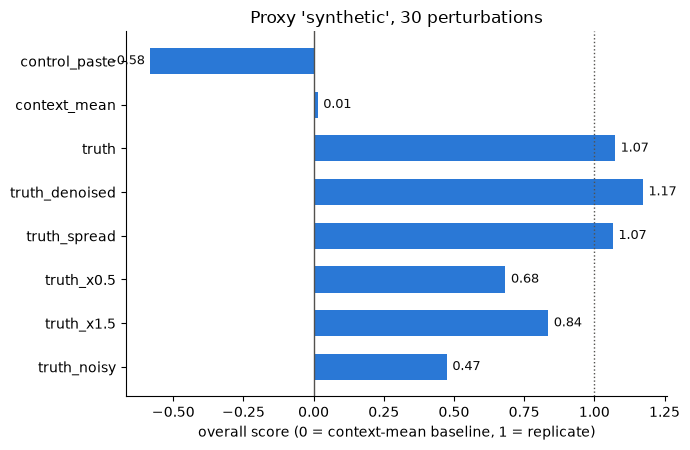

In [10]:
from matplotlib.colors import LinearSegmentedColormap

# Diverging colours: red = worse than the baseline (<0), grey = 0, blue = replicate level (≥1).
diverging = LinearSegmentedColormap.from_list("vcc", ["#e34948", "#f0efec", "#2a78d6"])
display(scores.style.format("{:.2f}").background_gradient(cmap=diverging, vmin=-1, vmax=1, axis=None)
        .set_caption("Scaled scores (leaderboard scale)"))
display(raw.style.format("{:.3f}").set_caption("Raw metric values"))

# One bar per prediction: the overall score.
fig, ax = plt.subplots(figsize=(7, 0.45 * len(scores) + 1))
ax.barh(scores.index[::-1], scores["overall"][::-1], color="#2a78d6", height=0.6)
ax.axvline(0, color="#52514e", lw=1)
ax.axvline(1, color="#52514e", lw=1, ls=":")
for y, v in enumerate(scores["overall"][::-1]):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right",
            color="#0b0b0b", fontsize=9)
ax.set_xlabel("overall score (0 = context-mean baseline, 1 = replicate)")
ax.set_title(f"Proxy '{PROXY}', {len(proxy_perts)} perturbations")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## 8. How to read the table

* **`truth` vs `truth_denoised`.** The measured mean of 400 cells wobbles by chance on every gene. `truth` feeds
  those wobbles to the generator as if they were real effects, which then adds fresh noise on top, so extra genes
  come out significant and `jac` suffers. That is also why *shrinking* (`truth_x0.5`) can raise `jac`: it shrinks
  the wobbles too, at a heavy cost in `fid`. `truth_denoised` keeps only clear changes and is the realistic
  ceiling for a model (models predict smooth effects, not the dataset's noise). Lesson for modelling: **predict
  "no change" for genes you are not confident about**, rather than small random-looking changes.
* On the synthetic proxy these ceilings are optimistic (the truth was made with the same machinery), so values
  near 1 there only prove the pipeline works. On the H1 proxy, a `truth_denoised` well below 1 on `fid`/`jac`
  means the generator, not the model, is the bottleneck.
* **`truth` vs `truth_spread`** (same means) isolates cell-to-cell spread. If spread clearly raises `jac`/`fid`
  *on the H1 proxy*, real perturbed cells respond more unevenly than our default generator assumes, and the
  submission should use that spread (`build_submission(..., spread=…)`). On the synthetic proxy this comparison is
  circular, because the synthetic truth itself was made with spread 0.5.
* **`truth_x0.5` vs `truth`** shows the cost of **shrunken** predictions, the typical failure of models that
  average things (neighbour averaging, heavy regularization). Too-small effects mean too few significant genes;
  `fid` punishes that hard (its scale is the narrowest of the six) and `nmae` rises.
* **`truth_x1.5`** shows the cost of **inflated** effects: `nmae` (fold-change error grows linearly), `mse`, and
  over-calling in `jac`.
* **`truth_noisy`**: random errors on *every* gene wipe out `mse` (down to its 0 floor) and cost `fid` and `jac`
  through invented significant genes.
* **`control_paste`** calls no genes at all, so `fid` is deeply negative; never submit something like it.

Per-perturbation details for any prediction are in `work/.../run_<name>/results.csv`
(columns: `perturbation, metric, value`), useful for finding which targets lose points.

## 9. Writing a real VCC submission

The upload format (checked by `vcc prep`): one `.h5ad` with all contexts; `obs` columns `target_gene`
(gene symbol) and `context`; exactly 400 cells per target per context; the 18,533 genes in `gene_names.csv`
order; raw integer counts; ≤ 1,000,000 counts per cell; **no** non-targeting rows; stored sparse.

`build_submission` below does all of that for any model that returns predicted mean CPM per target. The
placeholder model just copies the controls. **It is a format test only; never submit it.** (On the A/B/C
leaderboard such a file would score about −0.3; on the synthetic proxy in §7 it scored lower because the proxy
has its own scale ends.)

* On the Mac it runs a tiny version (5 cells per target) and checks the format with `vcc prep --dry-run`.
* The full file (360,000 cells, ~2.1 billion stored values, ~50 GB peak memory) must be built on TSUBAME
  (`node_q` or larger).

In [11]:
def placeholder_model(ctx, targets, ctrl_mean_ctx):
    """A stand-in model: predicts 'no change' for every target. Replace with a real model.
    Must return an array (len(targets), n_genes) of predicted mean CPM for context `ctx`."""
    return np.tile(ctrl_mean_ctx, (len(targets), 1))


def build_submission(model, controls_dir, out_path, cells_per_pert=CELLS_PER_PERT, spread=0.0, seed=SEED):
    """Generate predicted cells for every context and target, run the upload checks, and write the h5ad.
    Contexts come from the bundle's manifest and are processed by NAME (never by position) so their labels
    can't get swapped. `spread` is the generator's cell-to-cell spread (tune it on the H1 proxy, §7–8)."""
    r = np.random.default_rng(seed)
    ctxs = json.loads((controls_dir / "manifest.json").read_text())["contexts"]
    g_names = pd.read_csv(controls_dir / "gene_names.csv")["gene_name"].to_numpy()
    targets = pd.read_csv(controls_dir / "pert_counts.csv")["target_gene"].tolist()
    blocks, obs = [], []
    for ctx in ctxs:
        a = ad.read_h5ad(controls_dir / f"context_{ctx}.h5ad")
        assert (a.obs["context"] == ctx).all(), f"context_{ctx}.h5ad holds another context's cells!"
        assert list(a.var_names) == list(g_names)
        Xc = a.X.tocsr()
        cm = mean_cpm(Xc)
        g_ok = np.flatnonzero(cm > 5)
        pred_cpm = model(ctx, targets, cm)
        for p, t in enumerate(targets):
            block = generate_cells(pred_cpm[p], Xc, cm, cells_per_pert, r, spread=spread, gated=g_ok)
            assert not np.modf(block.data)[0].any(), "counts must be whole numbers"   # checked per block: cheap
            blocks.append(block)
            obs += [(t, ctx)] * cells_per_pert
        print(f"  context {ctx}: {len(targets)} targets × {cells_per_pert} cells generated")
    X = sp.vstack(blocks).tocsr()
    del blocks                                            # free the per-target copies before the checks
    X.eliminate_zeros()                                   # explicit zeros count against the density cap
    sub = ad.AnnData(X=X, obs=pd.DataFrame(obs, columns=["target_gene", "context"],
                                           index=[f"c{i}" for i in range(len(obs))]),
                     var=pd.DataFrame(index=g_names))
    # The same checks vcc prep makes, so problems surface before writing a multi-GB file.
    assert X.data.min() >= 0, "counts must be non-negative"
    assert np.asarray(X.sum(axis=1)).max() <= 1_000_000, "a cell exceeds 1,000,000 counts"
    assert X.nnz <= 4_750_000_000, "too many stored entries"
    assert "non-targeting" not in set(sub.obs["target_gene"])
    sub.write_h5ad(out_path, compression="gzip")
    print(f"wrote <project>/{Path(out_path).relative_to(PROJECT)}  "
          f"({sub.n_obs:,} cells, {X.nnz / sub.n_obs:,.0f} stored entries per cell)")
    return out_path, ctxs


small = MODE == "local_small"
sub_path = WORK / ("submission_format_test.h5ad" if small else "submission_placeholder.h5ad")
sub_path, sub_contexts = build_submission(placeholder_model, SUBMIT_DIR, sub_path, cells_per_pert=5 if small else 400)

# Validate exactly like the platform will (nothing is uploaded or written with --dry-run).
# vcc 0.2.2 assumes contexts A,B,C unless told otherwise, so always pass --contexts explicitly.
prep_cmd = [VCC, "prep", os.path.relpath(sub_path), "-g", SUBMIT_DIR / "gene_names.csv",
            "--perts", SUBMIT_DIR / "pert_counts.csv",
            "--contexts", ",".join(sub_contexts), "--dry-run"]
if small:
    prep_cmd += ["--cells-per-pert", "5"]
print(run_cmd(prep_cmd).stdout)

  context A: 300 targets × 5 cells generated


  context B: 300 targets × 5 cells generated


  context C: 300 targets × 5 cells generated


wrote <project>/work/harness_synthetic_local_small/submission_format_test.h5ad  (4,500 cells, 5,984 stored entries per cell)


  vcc prep … exit=0  (2 s)
✓ dry run — no .vcc written
  input:         ../work/harness_synthetic_local_small/submission_format_test.h5ad
  output:        (dry run)
  cells:         4500
  genes:         18533  (encoding: float32)
  perturbations: column 'target_gene' → 'target_gene'
  contexts:      column 'context' → A=1500, B=1500, C=1500
  targets:       verified against the official list
  normalization: counts-preserved



**Submitting a real model's file** (on TSUBAME, after `vcc login`). `vcc prep` loads the whole file into
memory (~20–26 GB), so run it **on a compute node** (inside the batch job, `qrsh`, or an Open OnDemand
session), not on a login node (4 GB limit). `vcc submit` of the finished `.vcc` is light.

```bash
# validation phase (A/B/C)
vcc prep submission.h5ad -g controls/gene_names.csv --perts controls/pert_counts.csv --contexts A,B,C -o submission.vcc
# final phase (D/E/F): use the NEW bundle folder for all three files, and say --contexts D,E,F
vcc prep submission.h5ad -g <DEF_folder>/gene_names.csv --perts <DEF_folder>/pert_counts.csv --contexts D,E,F -o submission.vcc
vcc submit submission.vcc -m "model name" -d "short description" --wait
```

For the final phase, unzip the D/E/F bundle into **`controls_DEF/`** (git ignores it) and set
`SUBMIT_DIR = PROJECT / "controls_DEF"` in §1. `CONTROLS_DIR` stays pointed at the A/B/C controls used for the proxy.

## 10. Running on TSUBAME 4.0

Facts below come from the official TSUBAME 4.0 handbook (https://www.t4.cii.isct.ac.jp/docs/handbook.en/).

**The machine.** Each node has 4 × NVIDIA H100 (94 GB), 192 CPU cores, 768 GB RAM. You rent a slice of one:

| resource | GPUs | cores | RAM | charge coef. | good for |
|---|---|---|---|---|---|
| `gpu_1` | 1 | 8 | 96 GB | 0.20 | `local_small` runs (~10 min ≈ 0.04 points), development |
| `node_q` | 1 | 48 | 192 GB | 0.25 | **this notebook at full size**, building submissions |
| `node_f` | 4 | 192 | 768 GB | 1.00 | large datasets (e.g. 66 GB K562 genome-wide), training on 4 GPUs |
| free interactive queue (`iqrsh`, or group "Free" in Open OnDemand) | ½ (MIG) | 24 | 96 GB | free on campus | setup, editing, light Jupyter work. **Shared by up to 12 users** |

Points = coef × (0.7 × used hours + 0.1 × requested hours); jobs are billed at least 5 minutes; max 24 h per job.
A faculty or staff member must create the TSUBAME group (`tga-…`) and buy points (1,000 JPY = 16 points on campus).

**One-time steps**
1. Get an account via the TSUBAME portal (https://portal.t4.gsic.titech.ac.jp/ptl/) and register an **ed25519**
   SSH key.
2. The group owner buys **group disk** (`/gs/bs`, 1 TB units, 0.5 points per TB per month); check with
   `t4-user-info disk group`. Home + work space is only 125 GiB in total, and nothing is backed up.
3. Log in (`ssh <login>@login.t4.gsic.titech.ac.jp`) and give TSUBAME its own SSH key for GitHub
   (`ssh-keygen -t ed25519 -f ~/.ssh/id_ed25519_github`, add the `.pub` to your GitHub account, and put
   `Host github.com` / `IdentityFile ~/.ssh/id_ed25519_github` in `~/.ssh/config`).
4. On a compute node, make **your own** clone (shared clones break each other's `.venv` and outputs), run the setup
   script (creates `.venv` with the GPU scorer, installs the `vcc` CLI, registers the `vcc` kernel), log in to
   vcc yourself, and download the controls (they are not in git). There is no desktop keychain on the cluster, so
   `vcc login --store-plaintext` keeps the key in a private 0600 file. Never put the key in a notebook, a job
   script, or the project folder.
   ```bash
   iqrsh -l h_rt=1:00:00                     # free (on campus); or: qrsh -g <group> -l gpu_1=1 -l h_rt=1:00:00
   mkdir -p /gs/bs/<group>/$USER && cd /gs/bs/<group>/$USER
   git clone git@github.com:danialsj77/VCC.git && cd VCC && bash tsubame/setup_env.sh
   vcc login --store-plaintext               # paste your key at the hidden prompt
   vcc datasets download controls -d . && unzip -o vcc_2026_controls.zip -d controls
   ```
5. Download big public datasets **once** for the whole team into `/gs/bs/<group>/shared/data` and link them into
   each clone: `ln -s /gs/bs/<group>/shared/data data`.

**Interactive (Jupyter in the browser):** https://ood.t4.cii.isct.ac.jp/ → Interactive Apps → Jupyter → choose
`node_q`, your group and a run time → Launch → open this notebook and select the **vcc** kernel. Open OnDemand
sessions don't see `VCC_MODE`, so **edit §1 to `MODE = os.environ.get("VCC_MODE", "tsubame_full")`**, then
*Restart Kernel and Run All Cells*. A running session is billed even when idle; delete it when done. Never run
Jupyter on the login nodes (prohibited).

**Batch (unattended, full size)**, from the project folder:
```bash
qsub -g <your-group> tsubame/run_notebook.sh                          # synthetic proxy, up to 300 perturbations
qsub -g <your-group> -v VCC_PROXY=h1_2025 tsubame/run_notebook.sh     # real-biology proxy
qstat                                                                  # check the job
```
The job saves the executed notebook after **every** cell (papermill), as
`work/runs/01_local_evaluation_harness.<proxy>.<jobid>.ipynb`, so even a failed or timed-out job leaves its
tables up to the failure. Logs: `vcc_harness.o<jobid>`, `work/.../log_*.txt`, `work/.../run_*.log`.
Tip: download the H1 data beforehand on the free queue, so the paid job doesn't spend time downloading:
`mkdir -p /gs/bs/<group>/shared/data/h1_2025 && cd /gs/bs/<group>/shared/data/h1_2025`, then `curl -fLO` each of
the three URLs from §4b (with `data` linked into your clone as in step 5).

**Big datasets:** keep them under `/gs/bs/<group>/…`, and for heavy jobs copy them to the node's fast local
disk first (`cp … $T4TMPDIR/`; up to 415 GB on `node_q`, 1.6 TB on `node_f`, deleted when the job ends).